# Air Raid Alert Duration — Kyiv Oblast

Historical one-day-ahead forecasting experiment. **Not a safety warning or an operational prediction system.**

Data: [Ukrainian Air Raid Sirens Dataset](https://github.com/Vadimkin/ukrainian-air-raid-sirens-dataset), volunteer_data_en.csv. Frozen snapshot acquired **2026-10-11 12:18:26 Europe/Kyiv**. Analysis ends **2026-10-09**, with the last 30 calendar days reserved as final test. The snapshot may contain retrospective updates; we cannot independently verify when each event was first published.

**Before Run all in Colab:** upload `air_raid_source_snapshot.csv` using the left **Files** panel. Both files must be in the working directory. The CSV is intentionally not downloaded dynamically. See README for setup.

In [22]:
import hashlib
from pathlib import Path
import pandas as pd
from IPython.display import display

SOURCE_URL = "https://raw.githubusercontent.com/Vadimkin/ukrainian-air-raid-sirens-dataset/main/datasets/volunteer_data_en.csv"
SNAPSHOT_ACQUIRED_KYIV = "2026-10-11T12:18:26.279092+03:00"
EXPECTED_SHA256 = "e403ece29651a1ffe674b1fb6afa72264c76070d6ff57686432f9c07f78fb4f0"
SNAPSHOT_FILE = Path("air_raid_source_snapshot.csv")

if not SNAPSHOT_FILE.exists():
    raise FileNotFoundError("Upload air_raid_source_snapshot.csv using the Colab Files panel before running this notebook.")

actual_sha256 = hashlib.sha256(SNAPSHOT_FILE.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, "CSV differs from the frozen snapshot; do not overwrite the original."

df = pd.read_csv(SNAPSHOT_FILE)
required = {"region", "started_at", "finished_at", "naive"}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
for column in ["started_at", "finished_at"]:
    df[column] = pd.to_datetime(df[column], utc=True, format="mixed", errors="raise")

print("Snapshot acquired (Kyiv):", SNAPSHOT_ACQUIRED_KYIV)
print("SHA256 verified:", actual_sha256)
print("Rows:", len(df))
print("Timestamp types:\n", df[["started_at", "finished_at"]].dtypes)
print("Most recent start (UTC):", df["started_at"].max())
display(df.head())


Snapshot acquired (Kyiv): 2026-10-11T12:18:26.279092+03:00
SHA256 verified: e403ece29651a1ffe674b1fb6afa72264c76070d6ff57686432f9c07f78fb4f0
Rows: 115989
Timestamp types:
 started_at     datetime64[ns, UTC]
finished_at    datetime64[ns, UTC]
dtype: object
Most recent start (UTC): 2026-10-11 04:36:59+00:00


,region,started_at,finished_at,naive
0,Kyiv City,2022-02-25 16:36:22+00:00,2022-02-25 17:06:22+00:00,True
1,Cherkaska oblast,2022-02-25 18:36:21+00:00,2022-02-25 19:32:11+00:00,False
2,Rivnenska oblast,2022-02-25 18:56:44+00:00,2022-02-25 19:26:44+00:00,True
3,Zaporizka oblast,2022-02-25 18:57:51+00:00,2022-02-25 19:27:51+00:00,True
4,Volynska oblast,2022-02-25 19:41:57+00:00,2022-02-26 04:01:55+00:00,False


In [23]:

# Select Kyiv Oblast only
kyiv = df[df["region"] == "Kyivska oblast"].copy()

# Sort by alert start time
kyiv = kyiv.sort_values("started_at").reset_index(drop=True)

# Check data quality
print("Total alerts:", len(kyiv))

print("\nMissing values:")
print(kyiv.isna().sum())

print("\nDuplicate rows:", kyiv.duplicated().sum())

invalid = (
    kyiv["finished_at"].notna()
    & (kyiv["finished_at"] < kyiv["started_at"])
)
print("End before start:", invalid.sum())

print("\nNaive values:")
print(kyiv["naive"].value_counts(dropna=False))

# Check time coverage
print("\nFirst alert:", kyiv["started_at"].min())
print("Last alert start:", kyiv["started_at"].max())
print("Last alert end:", kyiv["finished_at"].max())

# Count alerts crossing midnight in Kyiv time

# Convert UTC timestamps to Kyiv local time
start_local = kyiv["started_at"].dt.tz_convert("Europe/Kyiv")
end_local = kyiv["finished_at"].dt.tz_convert("Europe/Kyiv")


cross_midnight = (
    start_local.notna()
    & end_local.notna()
    & (start_local.dt.date != end_local.dt.date)
)

print("Alerts crossing midnight:", cross_midnight.sum())


Total alerts: 4455

Missing values:
region         0
started_at     0
finished_at    0
naive          0
dtype: int64

Duplicate rows: 0
End before start: 0

Naive values:
naive
False    4319
True      136
Name: count, dtype: int64

First alert: 2022-02-27 06:21:39+00:00
Last alert start: 2026-10-11 01:25:43+00:00
Last alert end: 2026-10-11 01:33:52+00:00
Alerts crossing midnight: 134


In [24]:

# Check overlapping alerts
previous_end = kyiv["finished_at"].cummax().shift(1)
overlaps = kyiv["started_at"] < previous_end

print("Overlapping intervals:", overlaps.sum())

# Convert dates to Kyiv time
kyiv["start_local"] = kyiv["started_at"].dt.tz_convert(
    "Europe/Kyiv"
)

kyiv["date"] = kyiv["start_local"].dt.date

# Count recent alert starts
daily_counts = kyiv.groupby("date").size()

recent_dates = pd.date_range(
    end=kyiv["date"].max(),
    periods=14,
    freq="D"
)

recent_counts = daily_counts.reindex(
    recent_dates.date,
    fill_value=0
)

print("\nLast 14 days:")
print(recent_counts.to_string())

print("\nNaive records by year:")
print(
    kyiv.groupby(kyiv["start_local"].dt.year)["naive"]
    .agg(["sum", "count"])
)


Overlapping intervals: 0

Last 14 days:
date
2026-09-28    13
2026-09-29    14
2026-09-30     9
2026-10-01    17
2026-10-02    18
2026-10-03    13
2026-10-04    17
2026-10-05    13
2026-10-06    15
2026-10-07    11
2026-10-08     9
2026-10-09    16
2026-10-10    12
2026-10-11     6

Naive records by year:
             sum  count
start_local            
2022          10    507
2023          14    531
2024          42   1012
2025          31    923
2026          39   1482


In [25]:

# STEP 4: Inspect the newest records

# Display the last 15 alerts in Kyiv local time
recent_alerts = kyiv.tail(15).copy()

recent_alerts["started_at"] = (
    recent_alerts["started_at"]
    .dt.tz_convert("Europe/Kyiv")
)

recent_alerts["finished_at"] = (
    recent_alerts["finished_at"]
    .dt.tz_convert("Europe/Kyiv")
)

print("Last 15 alerts:")
display(recent_alerts[
    ["started_at", "finished_at", "naive"]
])

# Show alert counts by date in the full dataset
# (all regions, not only Kyiv Oblast)

all_dates = (
    df["started_at"]
    .dt.tz_convert("Europe/Kyiv")
    .dt.date
)

print("\nAll regions - last 7 dates with alert starts:")
print(
    df.groupby(all_dates)
    .size()
    .tail(7)
)


print("\nSnapshot acquired (Kyiv):", SNAPSHOT_ACQUIRED_KYIV)



Last 15 alerts:


,started_at,finished_at,naive
4440,2026-10-10 08:25:13+03:00,2026-10-10 08:33:08+03:00,False
4441,2026-10-10 08:34:54+03:00,2026-10-10 09:21:38+03:00,False
4442,2026-10-10 12:44:41+03:00,2026-10-10 13:00:52+03:00,False
4443,2026-10-10 14:08:09+03:00,2026-10-10 14:36:23+03:00,False
4444,2026-10-10 18:49:46+03:00,2026-10-10 19:01:01+03:00,False
4445,2026-10-10 19:07:22+03:00,2026-10-10 19:52:09+03:00,False
4446,2026-10-10 21:01:13+03:00,2026-10-10 21:07:48+03:00,False
4447,2026-10-10 21:22:07+03:00,2026-10-10 21:26:51+03:00,False
4448,2026-10-10 23:04:29+03:00,2026-10-10 23:29:13+03:00,False
4449,2026-10-11 00:06:19+03:00,2026-10-11 00:21:15+03:00,False



All regions - last 7 dates with alert starts:
started_at
2026-10-05    141
2026-10-06    155
2026-10-07    157
2026-10-08    147
2026-10-09    192
2026-10-10    197
2026-10-11     60
dtype: int64

Snapshot acquired (Kyiv): 2026-10-11T12:18:26.279092+03:00


In [26]:

# STEP 5: Calculate daily alert duration

from datetime import timedelta

TZ = "Europe/Kyiv"
CUTOFF = pd.Timestamp("2026-10-10", tz=TZ)

daily_minutes = {}

for _, alert in kyiv.iterrows():
    start = alert["started_at"].tz_convert(TZ)
    end = alert["finished_at"].tz_convert(TZ)

    # Don't include time after the chosen cutoff
    if start >= CUTOFF:
        continue

    end = min(end, CUTOFF)

    # Split alerts that cross midnight
    while start < end:
        next_midnight = pd.Timestamp(
            start.date() + timedelta(days=1),
            tz=TZ
        )

        segment_end = min(end, next_midnight)
        minutes = (segment_end - start).total_seconds() / 60

        day = start.date()
        daily_minutes[day] = (
            daily_minutes.get(day, 0) + minutes
        )

        start = segment_end

# Create one row for every calendar day
all_days = pd.date_range(
    start=kyiv["started_at"].min().tz_convert(TZ).date(),
    end=pd.Timestamp("2026-10-09"),
    freq="D"
)

daily = pd.DataFrame({"date": all_days.date})

daily["alert_minutes"] = (
    daily["date"].map(daily_minutes)
)

# Keep missing days as unknown for now
print("Total calendar days:", len(daily))
print("Days with recorded alert duration:",
      daily["alert_minutes"].notna().sum())
print("Days without recorded duration:",
      daily["alert_minutes"].isna().sum())

print("\nFirst 5 days:")
display(daily.head())

print("\nLast 10 days:")
display(daily.tail(10))



Total calendar days: 1686
Days with recorded alert duration: 1426
Days without recorded duration: 260

First 5 days:


,date,alert_minutes
0,2022-02-27,90.000000
1,2022-02-28,328.233333
2,2022-03-01,1024.916667
3,2022-03-02,573.333333
4,2022-03-03,49.833333



Last 10 days:


,date,alert_minutes
1676,2026-09-30,139.333333
1677,2026-10-01,269.400000
1678,2026-10-02,331.050000
1679,2026-10-03,173.333333
1680,2026-10-04,249.750000
1681,2026-10-05,277.933333
1682,2026-10-06,308.400000
1683,2026-10-07,192.016667
1684,2026-10-08,254.933333
1685,2026-10-09,161.816667


In [27]:

# STEP 6: Investigate missing days

daily["date"] = pd.to_datetime(daily["date"])
daily["year"] = daily["date"].dt.year

# Missing days by year
yearly_quality = daily.groupby("year").agg(
    total_days=("date", "count"),
    recorded_days=("alert_minutes", "count")
)

yearly_quality["missing_days"] = (
    yearly_quality["total_days"]
    - yearly_quality["recorded_days"]
)

yearly_quality["coverage_percent"] = (
    yearly_quality["recorded_days"]
    / yearly_quality["total_days"] * 100
).round(1)

print("Data coverage by year:")
display(yearly_quality)

# Find consecutive days without records
missing = daily["alert_minutes"].isna()

groups = missing.ne(missing.shift()).cumsum()

missing_periods = (
    daily[missing]
    .groupby(groups[missing])
    .agg(
        start=("date", "min"),
        end=("date", "max"),
        days=("date", "count")
    )
    .sort_values("days", ascending=False)
)

print("\nLongest periods without recorded alerts:")
display(missing_periods.head(10))


Data coverage by year:


,total_days,recorded_days,missing_days,coverage_percent
year,,,,
2022,308,233,75,75.6
2023,365,264,101,72.3
2024,366,333,33,91.0
2025,365,332,33,91.0
2026,282,264,18,93.6



Longest periods without recorded alerts:


,start,end,days
alert_minutes,,,
98,2023-01-07,2023-01-13,7
20,2022-06-29,2022-07-04,6
80,2022-11-24,2022-11-28,5
160,2023-06-28,2023-07-01,4
144,2023-04-22,2023-04-25,4
52,2022-09-17,2022-09-19,3
56,2022-09-23,2022-09-25,3
26,2022-07-20,2022-07-22,3
12,2022-04-30,2022-05-02,3


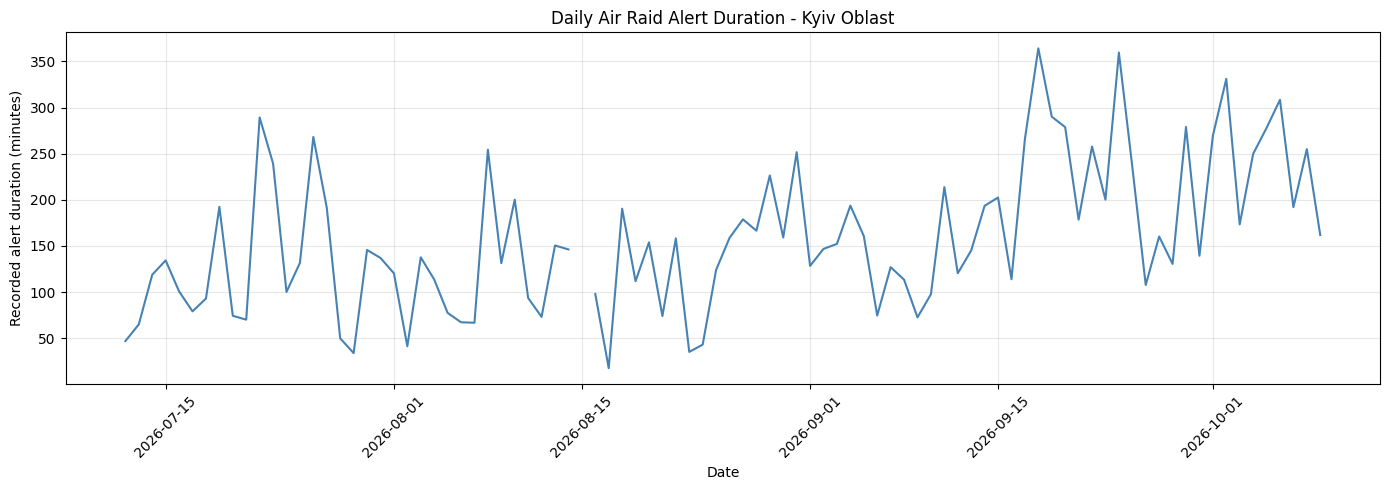

Average recorded duration (last 90 days):
158.47 minutes

Days without records in this period:
1


In [28]:

# STEP 7: Visualize daily alert duration

import matplotlib.pyplot as plt

# Select the last 90 calendar days
last_90 = daily.tail(90).copy()

plt.figure(figsize=(14, 5))

plt.plot(
    last_90["date"],
    last_90["alert_minutes"],
    color="steelblue",
    linewidth=1.5
)

plt.title("Daily Air Raid Alert Duration - Kyiv Oblast")
plt.xlabel("Date")
plt.ylabel("Recorded alert duration (minutes)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average recorded duration (last 90 days):")
print(round(last_90["alert_minutes"].mean(), 2), "minutes")

print("\nDays without records in this period:")
print(last_90["alert_minutes"].isna().sum())


In [29]:

# STEP 8: Check uncertain alert records

# Select naive=True alerts
uncertain = kyiv[kyiv["naive"] == True].copy()

# Calculate their duration
uncertain["duration_minutes"] = (
    uncertain["finished_at"] - uncertain["started_at"]
).dt.total_seconds() / 60

# Check records in our last 90 calendar days
period_start = pd.Timestamp(
    last_90["date"].min(),
    tz="Europe/Kyiv"
)

period_end = pd.Timestamp(
    last_90["date"].max() + pd.Timedelta(days=1),
    tz="Europe/Kyiv"
)

recent_uncertain = uncertain[
    (uncertain["started_at"] < period_end)
    & (uncertain["finished_at"] > period_start)
]

print("Total naive records:", len(uncertain))
print("Naive records overlapping last 90 days:",
      len(recent_uncertain))

print("\nNaive duration statistics:")
print(uncertain["duration_minutes"].describe())

print("\nRecent naive alerts:")
display(recent_uncertain[
    ["started_at", "finished_at", "duration_minutes"]
].tail(10))


Total naive records: 136
Naive records overlapping last 90 days: 8

Naive duration statistics:
count    136.0
mean      30.0
std        0.0
min       30.0
25%       30.0
50%       30.0
75%       30.0
max       30.0
Name: duration_minutes, dtype: float64

Recent naive alerts:


,started_at,finished_at,duration_minutes
3666,2026-07-12 14:23:30+00:00,2026-07-12 14:53:30+00:00,30.0
3668,2026-07-13 13:22:20+00:00,2026-07-13 13:52:20+00:00,30.0
3715,2026-07-23 19:04:54+00:00,2026-07-23 19:34:54+00:00,30.0
3736,2026-07-26 18:14:44+00:00,2026-07-26 18:44:44+00:00,30.0
3805,2026-08-10 16:15:50+00:00,2026-08-10 16:45:50+00:00,30.0
3862,2026-08-21 14:50:15+00:00,2026-08-21 15:20:15+00:00,30.0
3873,2026-08-24 06:40:30+00:00,2026-08-24 07:10:30+00:00,30.0
4134,2026-09-18 06:19:46+00:00,2026-09-18 06:49:46+00:00,30.0


In [30]:

# STEP 9: Mark uncertain daily observations

clean_daily = daily[[
    "date", "alert_minutes"
]].copy()

# Find local dates affected by naive intervals
uncertain_dates = set()

for _, alert in uncertain.iterrows():
    start = alert["started_at"].tz_convert("Europe/Kyiv")
    end = alert["finished_at"].tz_convert("Europe/Kyiv")

    while start < end:
        uncertain_dates.add(pd.Timestamp(start.date()))

        next_midnight = pd.Timestamp(
            start.date() + pd.Timedelta(days=1),
            tz="Europe/Kyiv"
        )
        start = min(end, next_midnight)

# Mark unreliable target values
clean_daily["uncertain"] = (
    clean_daily["date"].isin(uncertain_dates)
)

clean_daily["valid_target"] = (
    clean_daily["alert_minutes"].notna()
    & ~clean_daily["uncertain"]
)

# Keep uncertain and missing targets as NaN
clean_daily.loc[
    ~clean_daily["valid_target"],
    "alert_minutes"
] = float("nan")

# Restrict the main experiment to 2024 onward
model_daily = clean_daily[
    clean_daily["date"] >= "2024-01-01"
].copy().reset_index(drop=True)

print("Total days:", len(model_daily))
print("Valid target days:",
      model_daily["valid_target"].sum())
print("Missing or uncertain days:",
      (~model_daily["valid_target"]).sum())

print("\nLast 10 rows:")
display(model_daily.tail(10))


Total days: 1013
Valid target days: 825
Missing or uncertain days: 188

Last 10 rows:


,date,alert_minutes,uncertain,valid_target
1003,2026-09-30,139.333333,False,True
1004,2026-10-01,269.400000,False,True
1005,2026-10-02,331.050000,False,True
1006,2026-10-03,173.333333,False,True
1007,2026-10-04,249.750000,False,True
1008,2026-10-05,277.933333,False,True
1009,2026-10-06,308.400000,False,True
1010,2026-10-07,192.016667,False,True
1011,2026-10-08,254.933333,False,True
1012,2026-10-09,161.816667,False,True


In [31]:

# STEP 10: Build a 7-day baseline forecast

forecast_data = model_daily.copy()

# Use only the previous 7 calendar days
forecast_data["baseline_7d"] = (
    forecast_data["alert_minutes"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

# Forecasts we can compare with known targets
forecast_data["baseline_valid"] = (
    forecast_data["baseline_7d"].notna()
    & forecast_data["valid_target"]
)

# Reserve the last 30 calendar days for final testing
test_start = forecast_data["date"].max() - pd.Timedelta(
    days=29
)

development = forecast_data[
    forecast_data["date"] < test_start
].copy()

final_test = forecast_data[
    forecast_data["date"] >= test_start
].copy()

print("Final test starts:", test_start.date())
print("Development calendar days:", len(development))
print("Final test calendar days:", len(final_test))

print("\nValid baseline predictions in development:",
      development["baseline_valid"].sum())

print("Valid baseline predictions in final test:",
      final_test["baseline_valid"].sum())

print("\nDevelopment examples:")
display(
    development.loc[
        development["baseline_valid"],
        ["date", "alert_minutes", "baseline_7d"]
    ].tail(5)
)


Final test starts: 2026-09-10
Development calendar days: 983
Final test calendar days: 30

Valid baseline predictions in development: 230
Valid baseline predictions in final test: 22

Development examples:


,date,alert_minutes,baseline_7d
978,2026-09-05,160.750000,179.771429
979,2026-09-06,74.566667,170.390476
980,2026-09-07,127.000000,158.304762
981,2026-09-08,113.416667,140.497619
982,2026-09-09,72.533333,138.359524


Development period results:
Evaluated days: 230
7-day average MAE: 72.29 minutes
Previous-day MAE: 93.06 minutes


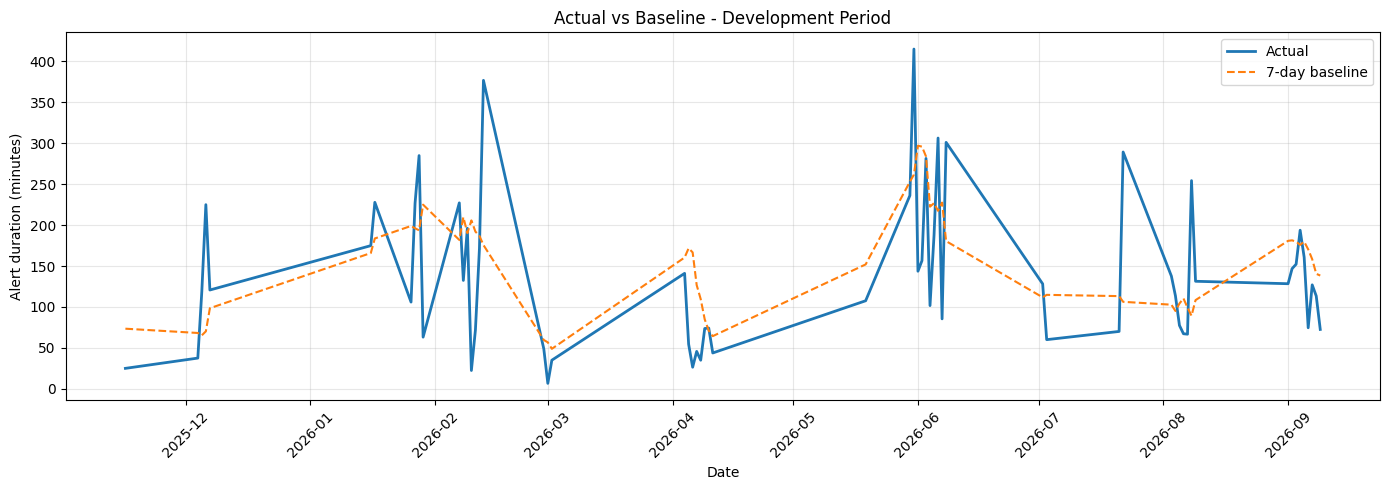

In [32]:

# STEP 11: Evaluate baseline on development data

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

dev = development.copy()

# Another simple forecast: previous day's duration
dev["previous_day"] = dev["alert_minutes"].shift(1)

# Use exactly the same dates for comparison
comparison = dev[
    dev["baseline_valid"]
    & dev["previous_day"].notna()
].copy()

y_true = comparison["alert_minutes"]
y_baseline = comparison["baseline_7d"]
y_previous = comparison["previous_day"]

mae_baseline = mean_absolute_error(y_true, y_baseline)
mae_previous = mean_absolute_error(y_true, y_previous)

print("Development period results:")
print("Evaluated days:", len(comparison))
print("7-day average MAE:", round(mae_baseline, 2), "minutes")
print("Previous-day MAE:", round(mae_previous, 2), "minutes")

# Plot recent development predictions
plot_data = comparison.tail(60)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["date"],
    plot_data["alert_minutes"],
    label="Actual",
    linewidth=2
)

plt.plot(
    plot_data["date"],
    plot_data["baseline_7d"],
    label="7-day baseline",
    linestyle="--"
)

plt.title("Actual vs Baseline - Development Period")
plt.xlabel("Date")
plt.ylabel("Alert duration (minutes)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [33]:

# STEP 12: Train and validate Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

ml_data = model_daily.copy()

# Create features using only past observations
for lag in range(1, 8):
    ml_data[f"lag_{lag}"] = (
        ml_data["alert_minutes"].shift(lag)
    )

features = [f"lag_{lag}" for lag in range(1, 8)]

# Use only development data with complete features
ml_dev = ml_data[
    (ml_data["date"] < test_start)
    & ml_data["valid_target"]
].dropna(subset=features).copy()

# Chronological validation: last 20% of eligible
# development samples, not a random split
split_idx = int(len(ml_dev) * 0.8)

train = ml_dev.iloc[:split_idx].copy()
validation = ml_dev.iloc[split_idx:].copy()

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(train[features], train["alert_minutes"])

rf_pred = model.predict(validation[features])

# Baseline on the exact same validation dates
baseline_pred = (
    validation[features].mean(axis=1)
)

rf_mae = mean_absolute_error(
    validation["alert_minutes"], rf_pred
)

baseline_mae = mean_absolute_error(
    validation["alert_minutes"], baseline_pred
)

print("Training days:", len(train))
print("Validation days:", len(validation))
print("Validation start:", validation["date"].min().date())
print("Validation end:", validation["date"].max().date())

print("\nRandom Forest MAE:", round(rf_mae, 2), "minutes")
print("7-day baseline MAE:", round(baseline_mae, 2), "minutes")


Training days: 184
Validation days: 46
Validation start: 2026-02-10
Validation end: 2026-09-09

Random Forest MAE: 66.11 minutes
7-day baseline MAE: 67.33 minutes


In [34]:

# STEP 13: Final evaluation on held-out test period

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Refit the selected model on all development samples
final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    ml_dev[features],
    ml_dev["alert_minutes"]
)

# Use only valid test samples with complete past features
test_data = ml_data[
    (ml_data["date"] >= test_start)
    & ml_data["valid_target"]
].dropna(subset=features).copy()

test_data["rf_prediction"] = final_model.predict(
    test_data[features]
)

test_data["baseline_prediction"] = (
    test_data[features].mean(axis=1)
)

rf_test_mae = mean_absolute_error(
    test_data["alert_minutes"],
    test_data["rf_prediction"]
)

baseline_test_mae = mean_absolute_error(
    test_data["alert_minutes"],
    test_data["baseline_prediction"]
)

print("FINAL TEST RESULTS")
print("Test observations:", len(test_data))
print("Random Forest MAE:", round(rf_test_mae, 2), "minutes")
print("7-day baseline MAE:", round(baseline_test_mae, 2), "minutes")

print("\nPredictions:")
display(test_data[[
    "date",
    "alert_minutes",
    "rf_prediction",
    "baseline_prediction"
]].tail(10))


FINAL TEST RESULTS
Test observations: 22
Random Forest MAE: 61.22 minutes
7-day baseline MAE: 64.84 minutes

Predictions:


,date,alert_minutes,rf_prediction,baseline_prediction
1003,2026-09-30,139.333333,143.260571,210.438095
1004,2026-10-01,269.400000,180.540917,201.745238
1005,2026-10-02,331.050000,165.432912,188.852381
1006,2026-10-03,173.333333,192.680455,202.454762
1007,2026-10-04,249.750000,202.376284,211.833333
1008,2026-10-05,277.933333,149.380941,224.619048
1009,2026-10-06,308.400000,206.984002,245.683333
1010,2026-10-07,192.016667,208.171767,249.885714
1011,2026-10-08,254.933333,210.275736,257.411905
1012,2026-10-09,161.816667,180.111809,255.345238


In [35]:

# STEP 14: Export predictions and check time features

# Verify lag features: only previous calendar days
for lag in range(1, 8):
    expected = ml_data["alert_minutes"].shift(lag)
    pd.testing.assert_series_equal(
        ml_data[f"lag_{lag}"],
        expected,
        check_names=False
    )

# Check chronological separation
assert ml_dev["date"].max() < test_start
assert test_data["date"].min() >= test_start

# Ensure both predictions are available
assert test_data[
    ["rf_prediction", "baseline_prediction"]
].notna().all().all()

# Save the final test predictions
export_columns = [
    "date",
    "alert_minutes",
    "rf_prediction",
    "baseline_prediction"
]

test_data[export_columns].to_csv(
    "test_predictions.csv",
    index=False
)

print("Lag checks passed!")
print("Chronological split checks passed!")
print("Predictions saved to test_predictions.csv")


Lag checks passed!
Chronological split checks passed!
Predictions saved to test_predictions.csv


## Interpretation & limitations

The daily target is the duration of recorded Kyiv Oblast alerts, split at local midnight in `Europe/Kyiv`. Days without recorded intervals remain missing, **not zero**. Days touched by `naive=True` estimated 30-minute intervals are excluded as targets. Valid targets still may be incomplete. Seven preceding **calendar** days are used for each eligible forecast; the evaluation is historical and assumes preceding daily totals were available then. Source publication timestamps are unavailable, so real-time availability and absence of publication-delay leakage are **not verified**.

The model and hyperparameters were selected using development/validation only. The final 30 calendar days are held out; the comparison covers only days with complete features and accepted targets. MAE is expressed in minutes. Do not tune the model against test performance.